# Labb1

Here you will determine the tariff for motorcycle insurance based on the data mcdata.csv. This assignment is
mostly based on section 2.4 in the book.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Check the validity of the statistical assumtions

For each of the three vehicle age classes

a) Produce a bar plot with the number of claims (ANTSKAD) on the x-axis and two sets of bars displaying
1) the natural logarithm of the number of policies with 0, 1 and 2 claims and 
2) the natural logarithm
of the number of claims predicted by a Poisson distribution (fitted to the data)



In [2]:
data = pd.read_csv("mccase.csv", sep=";")

age = data["FORDALD"]
no_of_claims = data["ANTSKAD"]

new_class = no_of_claims[age <= 1]
middle_class = no_of_claims[(age >= 2) & (age <= 4)]
old_class = no_of_claims[age >= 5]

claims = []
claim_categories = [0, 1, 2]

for i in claim_categories:
    new = (new_class == i).sum()
    middle = (middle_class == i).sum()
    old = (old_class == i).sum()
    claims.append([new, middle, old])

log_no_claims = np.log(claims)

2) the natural logarithm
of the number of claims predicted by a Poisson distribution (fitted to the data)

In [3]:
from distributions import predict_poisson

predicted = []

for k in claim_categories:
    new = predict_poisson(new_class, k)
    middle = predict_poisson(middle_class, k)
    old = predict_poisson(old_class, k)
    predicted.append([new, middle, old])

log_predicted = np.log(predicted)

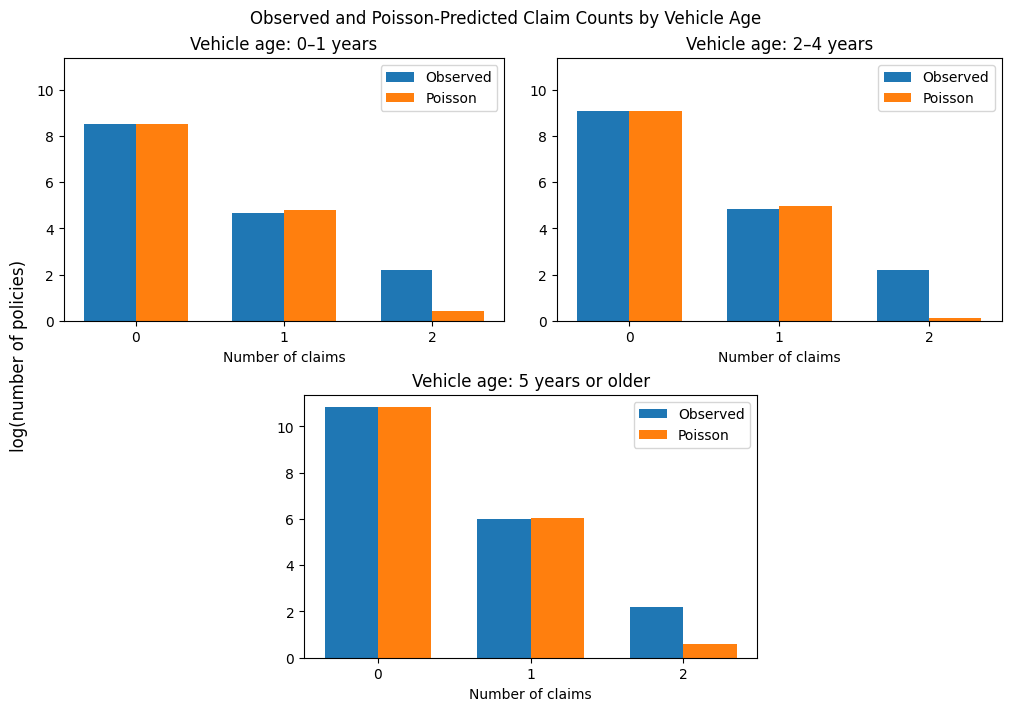

In [4]:
age_labels = ["0–1 years", "2–4 years", "5 years or older"]

fig = plt.figure(figsize=(10, 7), layout="constrained")
grid = fig.add_gridspec(2, 4)

top_left = fig.add_subplot(grid[0, 0:2])
top_right = fig.add_subplot(grid[0, 2:4], sharey=top_left)
bottom_center = fig.add_subplot(grid[1, 1:3], sharey=top_left)
axes = [top_left, top_right, bottom_center]

x = np.array(claim_categories)
width = 0.35

for j in range(3):
    axes[j].bar(x - width / 2, log_no_claims[:, j], width, label="Observed")
    axes[j].bar(x + width / 2, log_predicted[:, j], width, label="Poisson")

    axes[j].set_xticks(x)
    axes[j].set_xlabel("Number of claims")
    axes[j].set_title(f"Vehicle age: {age_labels[j]}")
    axes[j].legend()

fig.supylabel("log(number of policies)")
fig.suptitle("Observed and Poisson-Predicted Claim Counts by Vehicle Age")
plt.show()

b) Plot a histogram of the claim severities (for policies having a positive claim severity) together with a
Gamma pdf fitted to the data. Also, display the mean of the claim severity in the plot with a vertical
line

In [5]:
from distributions import fit_gamma

severity = data["SKADKOST"] / data["ANTSKAD"]
positive = data[severity > 0].copy()
positive["severity"] = severity[severity > 0]

age = positive["FORDALD"]
new = positive[age <= 1]
middle = positive[(age >= 2) & (age <= 4)]
old = positive[age >= 5]

groups = [new, middle, old]
plot_data = []

for group in groups:
    severity = group["severity"]
    x = np.linspace(severity.min(), severity.max(), 200)
    pdf = fit_gamma(x, severity, group["ANTSKAD"])
    plot_data.append((severity, x, pdf, severity.mean()))

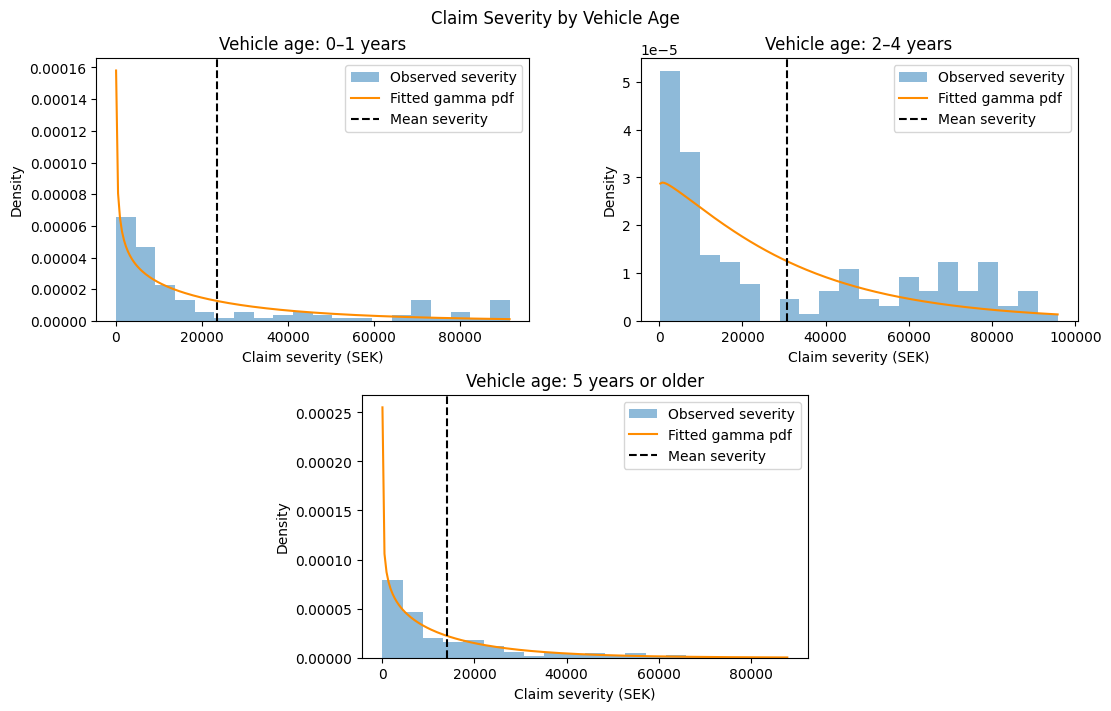

In [9]:
age_labels = ["0–1 years", "2–4 years", "5 years or older"]

fig = plt.figure(figsize=(11, 7), layout="constrained")
grid = fig.add_gridspec(2, 4)
axes = [
    fig.add_subplot(grid[0, 0:2]),
    fig.add_subplot(grid[0, 2:4]),
    fig.add_subplot(grid[1, 1:3])
]

for j in range(3):
    severity, x, pdf, mean = plot_data[j]
    ax = axes[j]

    ax.hist(severity, bins=20, density=True, alpha=0.5, label="Observed severity")
    ax.plot(x, pdf, color="darkorange", label="Fitted gamma pdf")
    ax.axvline(mean, color="black", linestyle="--", label="Mean severity")

    ax.set_title(f"Vehicle age: {age_labels[j]}")
    ax.set_xlabel("Claim severity (SEK)")
    ax.set_ylabel("Density")
    ax.legend()

fig.suptitle("Claim Severity by Vehicle Age")
plt.show()